# Dummy and logistic-regression OOF baseline

## tl;dr

- The prevalence dummy gives **0.4952 pooled OOF ROC-AUC** and **0.0184 average precision**. Its mean fold ROC-AUC is exactly **0.5000**.
- Logistic regression improves ranking to **0.5945 ROC-AUC** and **0.0418 average precision**, although performance remains modest.
- At the default 0.50 cutoff, both models predict every image as benign because the positive prevalence is only 1.86%.
- The logistic confusion matrix therefore also uses an explicitly exploratory OOF-selected threshold of approximately 0.027. It is useful for understanding the sensitivity/specificity trade-off, but it is not a final clinical threshold.


## Context & Methods

This notebook isolates two metadata-only baselines:

1. **Prevalence dummy** - predicts the malignant-image prevalence learned from each training fold.
2. **Unweighted logistic regression** - learns associations from sex, approximate age and anatomical site.

Every probability is **out-of-fold (OOF)**. For each of the five folds, the model is fitted on the other four folds and predicts only the held-out patients. No patient appears in both training and validation for the same prediction.

### Key Assumptions

- The target is image-level malignancy (`target`).
- `diagnosis` and `benign_malignant` are not predictors because they reveal the outcome.
- ROC-AUC measures ranking; average precision summarizes the precision-recall curve and should be compared with the 1.86% positive prevalence.
- Confusion matrices require a threshold. The 0.50 result is reported first. A second logistic threshold is selected from the OOF predictions by maximum balanced accuracy only to illustrate the trade-off. Because the same OOF labels select and summarize that threshold, its confusion matrix is descriptive rather than an unbiased final evaluation.
- The labelled subset test set is not loaded or evaluated.


## Data

### 1. Load the patient-safe training folds

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    log_loss,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
if not (PROJECT_ROOT / "pyproject.toml").exists():
    raise FileNotFoundError("Run this notebook from the project root or notebooks directory.")

DATA_PATH = PROJECT_ROOT / "data" / "subset" / "processed" / "train_folds.csv"
FEATURE_COLUMNS = [
    "sex",
    "age_approx",
    "anatom_site_general_challenge",
]
MODEL_LABELS = {
    "dummy": "Prevalence dummy",
    "logistic": "Logistic regression",
}
COLORS = {
    "dummy": "#94A3B8",
    "logistic": "#2563EB",
}


def build_logistic_metadata_pipeline(feature_columns=FEATURE_COLUMNS):
    '''Build the logistic pipeline directly in this standalone notebook.'''
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                list(feature_columns),
            )
        ],
        remainder="drop",
    )
    return Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                LogisticRegression(
                    C=1.0,
                    solver="liblinear",
                    max_iter=1_000,
                    random_state=42,
                ),
            ),
        ]
    )


def generate_oof_probabilities(
    frame,
    estimator,
    feature_columns=FEATURE_COLUMNS,
    *,
    target_col="target",
    fold_col="fold",
    group_col="patient_id",
    prediction_name="probability",
):
    '''Create validation probabilities while keeping each patient in one fold.'''
    features = list(feature_columns)
    if frame.groupby(group_col)[fold_col].nunique().gt(1).any():
        raise ValueError("At least one patient appears in multiple folds.")

    probabilities = np.full(len(frame), np.nan, dtype=float)
    for fold in sorted(frame[fold_col].unique()):
        validation_mask = frame[fold_col].eq(fold).to_numpy()
        training_mask = ~validation_mask
        fold_estimator = clone(estimator)
        fold_estimator.fit(
            frame.loc[training_mask, features],
            frame.loc[training_mask, target_col],
        )
        positive_class_position = list(fold_estimator.classes_).index(1)
        probabilities[validation_mask] = fold_estimator.predict_proba(
            frame.loc[validation_mask, features]
        )[:, positive_class_position]

    if np.isnan(probabilities).any():
        raise RuntimeError("At least one image did not receive an OOF prediction.")
    return pd.Series(probabilities, index=frame.index, name=prediction_name)


def binary_probability_metrics(targets, probabilities):
    '''Calculate the four probability metrics used in this notebook.'''
    return {
        "roc_auc": float(roc_auc_score(targets, probabilities)),
        "average_precision": float(average_precision_score(targets, probabilities)),
        "log_loss": float(log_loss(targets, probabilities, labels=[0, 1])),
        "brier_score": float(brier_score_loss(targets, probabilities)),
    }

train = pd.read_csv(DATA_PATH, dtype={"age_approx": "string"})
required_columns = {
    "image_name",
    "patient_id",
    "target",
    "fold",
    *FEATURE_COLUMNS,
}
missing_columns = required_columns - set(train.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

assert set(train["target"]) == {0, 1}, "The target must contain both binary classes."
assert set(train["fold"]) == {0, 1, 2, 3, 4}, "Expected five folds labelled 0-4."
assert train[FEATURE_COLUMNS].notna().all().all(), "Metadata contains missing values."
assert train.groupby("patient_id")["fold"].nunique().eq(1).all(), (
    "At least one patient appears in multiple folds."
)

print(f"Source: {DATA_PATH}")
print(f"Images: {len(train):,}")
print(f"Patients: {train['patient_id'].nunique():,}")
print(f"Malignant images: {int(train['target'].sum()):,} ({train['target'].mean():.2%})")
print(f"Features: {FEATURE_COLUMNS}")


Source: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\data\subset\processed\train_folds.csv
Images: 6,864
Patients: 422
Malignant images: 128 (1.86%)
Features: ['sex', 'age_approx', 'anatom_site_general_challenge']


## Results

### 2. Generate dummy and logistic OOF probabilities

In [2]:
estimators = {
    "dummy": DummyClassifier(strategy="prior"),
    "logistic": build_logistic_metadata_pipeline(),
}

oof_predictions = train[["image_name", "patient_id", "fold", "target"]].copy()
for model_name, estimator in estimators.items():
    probability_column = f"{model_name}_probability"
    oof_predictions[probability_column] = generate_oof_probabilities(
        train,
        estimator,
        FEATURE_COLUMNS,
        prediction_name=probability_column,
    )

probability_columns = [f"{model_name}_probability" for model_name in estimators]
assert oof_predictions[probability_columns].notna().all().all()
assert oof_predictions[probability_columns].apply(
    lambda values: values.between(0, 1).all()
).all()

print(f"Created OOF probabilities for {len(oof_predictions):,} images.")
print("Distinct dummy probabilities:")
print(np.sort(oof_predictions["dummy_probability"].unique()))


Created OOF probabilities for 6,864 images.
Distinct dummy probabilities:
[0.01856571 0.01857247 0.01860295 0.01874772 0.01875114]


### 3. Compare ROC-AUC and average precision

In [3]:
metric_rows = []
fold_metric_rows = []

for model_name in estimators:
    probability_column = f"{model_name}_probability"
    overall_metrics = binary_probability_metrics(
        oof_predictions["target"],
        oof_predictions[probability_column],
    )

    fold_auc_values = []
    for fold in sorted(oof_predictions["fold"].unique()):
        fold_mask = oof_predictions["fold"].eq(fold)
        fold_auc = roc_auc_score(
            oof_predictions.loc[fold_mask, "target"],
            oof_predictions.loc[fold_mask, probability_column],
        )
        fold_ap = average_precision_score(
            oof_predictions.loc[fold_mask, "target"],
            oof_predictions.loc[fold_mask, probability_column],
        )
        fold_auc_values.append(fold_auc)
        fold_metric_rows.append(
            {
                "Model": MODEL_LABELS[model_name],
                "Fold": int(fold),
                "ROC-AUC": fold_auc,
                "Average precision": fold_ap,
            }
        )

    metric_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Pooled OOF ROC-AUC": overall_metrics["roc_auc"],
            "Mean fold ROC-AUC": np.mean(fold_auc_values),
            "Average precision": overall_metrics["average_precision"],
        }
    )

metrics = pd.DataFrame(metric_rows).set_index("Model")
fold_metrics = pd.DataFrame(fold_metric_rows)

metrics.round(4)


,Pooled OOF ROC-AUC,Mean fold ROC-AUC,Average precision
Model,,,
Prevalence dummy,0.4952,0.500,0.0184
Logistic regression,0.5945,0.593,0.0418


In [4]:
dummy_fold_check = fold_metrics.query("Model == 'Prevalence dummy'").copy()
dummy_fold_check["Validation prevalence"] = (
    oof_predictions.groupby("fold")["target"].mean().to_numpy()
)
dummy_fold_check[["Fold", "ROC-AUC", "Average precision", "Validation prevalence"]].round(6)


,Fold,ROC-AUC,Average precision,Validation prevalence
0,0,0.5,0.018248,0.018248
1,1,0.5,0.018950,0.018950
2,2,0.5,0.018827,0.018827
3,3,0.5,0.018235,0.018235
4,4,0.5,0.018978,0.018978


### 4. Plot ROC and precision-recall curves

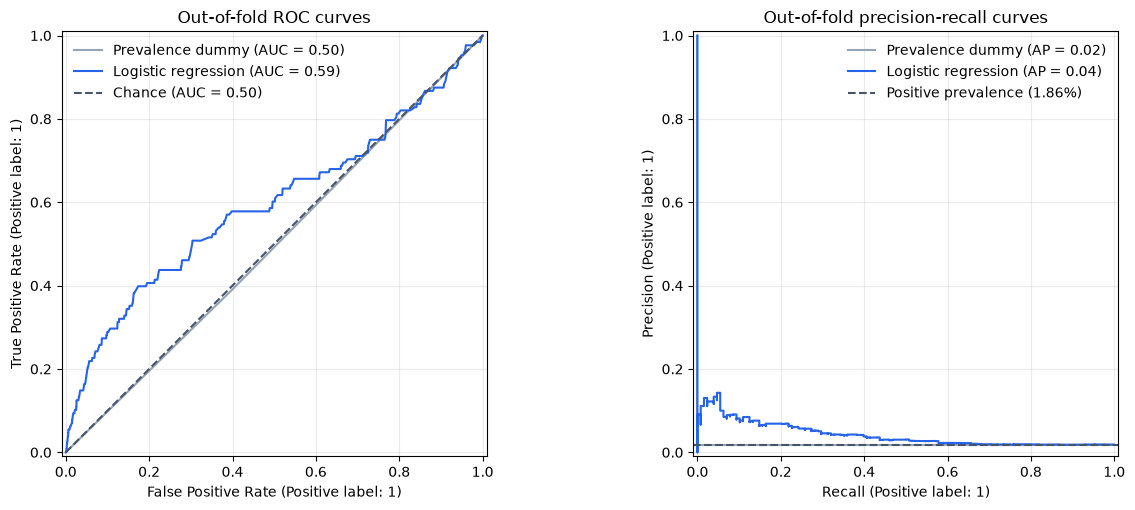

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for model_name in estimators:
    probability_column = f"{model_name}_probability"
    RocCurveDisplay.from_predictions(
        oof_predictions["target"],
        oof_predictions[probability_column],
        name=MODEL_LABELS[model_name],
        curve_kwargs={"color": COLORS[model_name]},
        ax=axes[0],
    )
    PrecisionRecallDisplay.from_predictions(
        oof_predictions["target"],
        oof_predictions[probability_column],
        name=MODEL_LABELS[model_name],
        curve_kwargs={"color": COLORS[model_name]},
        ax=axes[1],
    )

axes[0].plot([0, 1], [0, 1], linestyle="--", color="#475569", label="Chance (AUC = 0.50)")
axes[0].set_title("Out-of-fold ROC curves")
axes[0].legend(frameon=False)

positive_prevalence = train["target"].mean()
axes[1].axhline(
    positive_prevalence,
    linestyle="--",
    color="#475569",
    label=f"Positive prevalence ({positive_prevalence:.2%})",
)
axes[1].set_title("Out-of-fold precision-recall curves")
axes[1].legend(frameon=False)

for axis in axes:
    axis.grid(alpha=0.25)

fig.tight_layout()
plt.show()


### 5. Select thresholds for the confusion matrices

The conventional probability cutoff is 0.50. In this highly imbalanced dataset, neither model produces a probability above 0.50, so both classify every image as benign at that cutoff.

To make the logistic matrix informative, the notebook additionally selects the OOF threshold that maximizes balanced accuracy. This threshold is exploratory because the same OOF labels are used for selection and summarization. The dummy remains at 0.50 because it contains no ranking information and has no meaningful optimized decision threshold.


In [6]:
def select_balanced_accuracy_threshold(y_true, probabilities):
    candidates = np.unique(np.concatenate(([0.0], probabilities, [1.0])))
    scores = np.array(
        [balanced_accuracy_score(y_true, probabilities >= threshold) for threshold in candidates]
    )
    best_indices = np.flatnonzero(np.isclose(scores, scores.max()))
    best_index = best_indices[
        np.argmin(np.abs(candidates[best_indices] - 0.50))
    ]
    return float(candidates[best_index]), float(scores[best_index])


y_true = oof_predictions["target"].to_numpy()
logistic_probabilities = oof_predictions["logistic_probability"].to_numpy()
logistic_threshold, logistic_balanced_accuracy = select_balanced_accuracy_threshold(
    y_true,
    logistic_probabilities,
)

default_threshold_rows = []
for model_name in estimators:
    probabilities = oof_predictions[f"{model_name}_probability"].to_numpy()
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        probabilities >= 0.50,
        labels=[0, 1],
    ).ravel()
    default_threshold_rows.append(
        {"Model": MODEL_LABELS[model_name], "Threshold": 0.50, "TN": tn, "FP": fp, "FN": fn, "TP": tp}
    )

print("Default 0.50 threshold:")
display(pd.DataFrame(default_threshold_rows).set_index("Model"))
print(f"Exploratory logistic threshold: {logistic_threshold:.6f}")
print(f"Balanced accuracy at that OOF threshold: {logistic_balanced_accuracy:.4f}")


Default 0.50 threshold:


,Threshold,TN,FP,FN,TP
Model,,,,,
Prevalence dummy,0.5,6736,0,128,0
Logistic regression,0.5,6736,0,128,0


Exploratory logistic threshold: 0.027309
Balanced accuracy at that OOF threshold: 0.6124


### 6. Draw TN, FP, FN and TP as counts and percentages

Percentages are normalized within each actual class:

- TN and FP percentages add to 100% of actual benign images.
- FN and TP percentages add to 100% of actual malignant images.


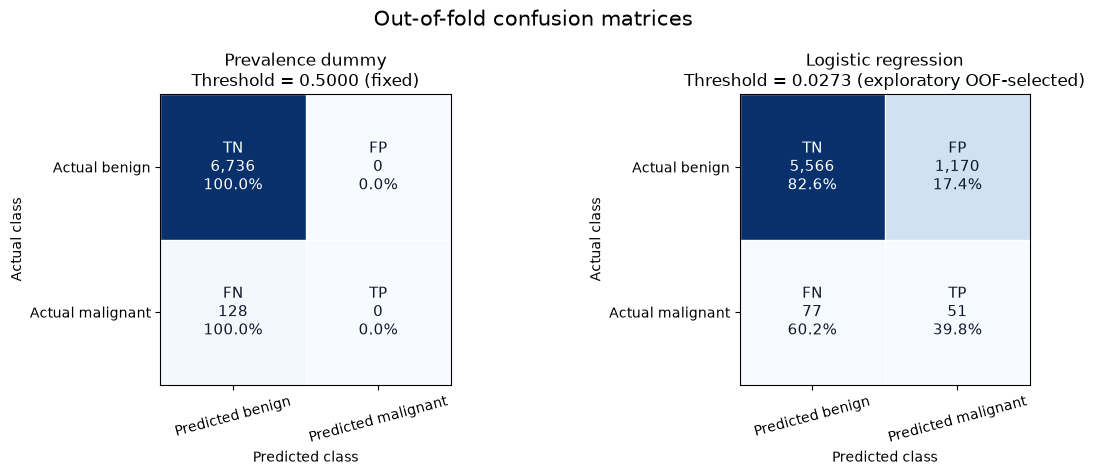

,Threshold,TN,TN % of actual benign,FP,FP % of actual benign,FN,FN % of actual malignant,TP,TP % of actual malignant,Precision among predicted malignant (%)
Model,,,,,,,,,,
Prevalence dummy,0.5000,6736,100.0,0,0.0,128,100.0,0,0.0,0.0
Logistic regression,0.0273,5566,82.6,1170,17.4,77,60.2,51,39.8,4.2


In [7]:
matrix_settings = {
    "dummy": 0.50,
    "logistic": logistic_threshold,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
confusion_rows = []

for axis, model_name in zip(axes, estimators):
    threshold = matrix_settings[model_name]
    probabilities = oof_predictions[f"{model_name}_probability"].to_numpy()
    predicted_labels = (probabilities >= threshold).astype(int)
    matrix = confusion_matrix(y_true, predicted_labels, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()

    row_percentages = matrix / matrix.sum(axis=1, keepdims=True) * 100
    annotations = np.array(
        [
            [
                f"TN\n{tn:,}\n{row_percentages[0, 0]:.1f}%",
                f"FP\n{fp:,}\n{row_percentages[0, 1]:.1f}%",
            ],
            [
                f"FN\n{fn:,}\n{row_percentages[1, 0]:.1f}%",
                f"TP\n{tp:,}\n{row_percentages[1, 1]:.1f}%",
            ],
        ]
    )
    axis.imshow(matrix, cmap="Blues")
    for row in range(2):
        for column in range(2):
            text_color = "white" if matrix[row, column] > matrix.max() / 2 else "#0F172A"
            axis.text(
                column,
                row,
                annotations[row, column],
                ha="center",
                va="center",
                color=text_color,
                fontsize=11,
            )
    axis.set_xticks([0, 1], labels=["Predicted benign", "Predicted malignant"])
    axis.set_yticks([0, 1], labels=["Actual benign", "Actual malignant"])
    axis.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    axis.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    axis.grid(which="minor", color="white", linestyle="-", linewidth=1)
    axis.tick_params(which="minor", bottom=False, left=False)
    threshold_description = "fixed" if model_name == "dummy" else "exploratory OOF-selected"
    axis.set_title(
        f"{MODEL_LABELS[model_name]}\nThreshold = {threshold:.4f} ({threshold_description})"
    )
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Actual class")
    axis.tick_params(axis="x", rotation=15)
    axis.tick_params(axis="y", rotation=0)

    confusion_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Threshold": threshold,
            "TN": tn,
            "TN % of actual benign": row_percentages[0, 0],
            "FP": fp,
            "FP % of actual benign": row_percentages[0, 1],
            "FN": fn,
            "FN % of actual malignant": row_percentages[1, 0],
            "TP": tp,
            "TP % of actual malignant": row_percentages[1, 1],
            "Precision among predicted malignant (%)": (
                tp / (tp + fp) * 100 if (tp + fp) else 0.0
            ),
        }
    )

fig.suptitle("Out-of-fold confusion matrices", fontsize=15)
fig.tight_layout()
plt.show()

confusion_results = pd.DataFrame(confusion_rows).set_index("Model")
confusion_results.round(
    {
        "Threshold": 4,
        "TN % of actual benign": 1,
        "FP % of actual benign": 1,
        "FN % of actual malignant": 1,
        "TP % of actual malignant": 1,
        "Precision among predicted malignant (%)": 1,
    }
)


## Takeaways

1. **The dummy is a no-skill reference.** It has exactly 0.5000 ROC-AUC within every fold. Its pooled value of 0.4952 comes from combining five slightly different training-fold prevalences.
2. **Logistic regression improves ranking.** ROC-AUC rises to 0.5945 and average precision rises from 0.0184 to 0.0418.
3. **ROC-AUC and average precision do not require a classification threshold.** They are more informative than accuracy for this imbalanced comparison.
4. **A 0.50 cutoff is inappropriate for interpreting these unweighted probabilities.** Both models predict every image as benign at that cutoff.
5. **The exploratory logistic threshold detects some malignant images but creates many false positives.** Its matrix illustrates the trade-off; it should not be treated as a clinically validated or final test-set threshold.
